In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# suppress warnings
pd.options.mode.chained_assignment = None
pd.options.mode.copy_on_write = True

In [2]:
plt.style.use('tableau-colorblind10') #Make sure plots are colorblind-accessible
hatches = ['/', '\\', '|', '-', '+', 'x', 'o', 'O', '.', '*']


**Data Cleaning**

In [3]:
jobs_demo = pd.read_csv('jobs_demo.csv', keep_default_na=False)
ai_jobs = pd.read_csv('ai_job_exposure.csv', keep_default_na=False)

In [4]:
# Summary statistics for ai_jobs
ai_jobs.describe()

,2025 National Employment Matrix title,2025 National Employment Matrix code,"Employment, 2025","Employment, 2035","Employment change, numeric, 2025–35","Employment change, percent, 2025–35","Percent self-employed, 2025","Occupational openings, 2025–35, annual average","Median annual wage, dollars, 2025",Typical education needed for entry,Work experience in a related occupation,Typical on-the-job training needed to attain competency in the occupation,Relative AI exposure
count,836,836,836,836,836,836,836,836,836,836,836,836,836
unique,836,814,654,664,297,255,213,300,778,9,4,7,5
top,Source: U.S. Bureau of Labor Statistics.,,31.2,14.5,0.4,4,—,0.3,—,High school diploma or equivalent,None,None,Low
freq,1,5,7,5,34,14,197,21,6,326,716,321,213


In [5]:
# Summary statistics for job_demo
jobs_demo.describe()

,Occupation,Total Employed,Women,White,Black or African American,Asian,Hispanic or Latino
count,602,602,602,602,602,602,602
unique,596,351,331,232,188,154,226
top,,10,–,–,–,–,–
freq,7,8,199,199,199,199,199


In [6]:
#Frequency of 'Typical on-the-job-training' values
ai_jobs['Typical on-the-job training needed to attain competency in the occupation'].value_counts()

,count
Typical on-the-job training needed to attain competency in the occupation,
None,321
Moderate-term on-the-job training,231
Short-term on-the-job training,174
Long-term on-the-job training,54
Internship/residency,36
Apprenticeship,15
,5


In [7]:
ai_jobs = ai_jobs.iloc[0:831, :] # rows with observations

#Rename columnns for readability
ai_jobs = ai_jobs.rename(columns = {'2025 National Employment Matrix title' : 'Occupation'})
ai_jobs = ai_jobs.rename(columns = {'Typical on-the-job training needed to attain competency in the occupation' : 'Typical on-the-job training'})
ai_jobs = ai_jobs.rename(columns = {'Work experience in a related occupation' : 'Related work experience'})
ai_jobs = ai_jobs.rename(columns = {'Typical education needed for entry' : 'Typical education'})

In [8]:
#Merge AI jobs and demographic data together based on matching occupation titles  Merge AI
joint_data = pd.merge(ai_jobs, jobs_demo, on='Occupation', how='inner')

In [9]:
#Remove commas and make string values float
ai_jobs['Employment, 2025'] = ai_jobs['Employment, 2025'].apply(lambda x: str(x).replace(',', ''))
ai_jobs['Employment, 2025'] = ai_jobs['Employment, 2025'].apply(lambda x: float(x))

ai_jobs['Employment, 2035'] = ai_jobs['Employment, 2035'].apply(lambda x: str(x).replace(',', ''))
ai_jobs['Employment, 2035'] = ai_jobs['Employment, 2035'].apply(lambda x: float(x))

ai_jobs['Employment change, percent, 2025–35'] = ai_jobs['Employment change, percent, 2025–35'].apply(lambda x: str(x).replace(',', ''))
ai_jobs['Employment change, percent, 2025–35'] = ai_jobs['Employment change, percent, 2025–35'].apply(lambda x: float(x))

In [10]:
# preparing to transform 'Women' to floats
joint_data['Women'] = joint_data['Women'].apply(lambda x: str(x).replace('–',''))
joint_data['Women'] = joint_data['Women'].apply(lambda x: x.strip())

joint_data['White'] = joint_data['White'].apply(lambda x: str(x).replace('–',''))
joint_data['White'] = joint_data['White'].apply(lambda x: x.strip())

In [11]:
# Removing empty rows
cleaned_joint = joint_data[joint_data['Women'] != '']

In [12]:
# transforming 'Women' to floats
cleaned_joint['Women'] = cleaned_joint['Women'].apply(lambda x: float(x))

In [13]:
# transforming 'White' to floats
cleaned_joint['White'] = cleaned_joint['White'].apply(lambda x: float(x))

In [14]:
# transforming 'Black or African American' to floats
cleaned_joint['Black or African American'] = cleaned_joint['Black or African American'].apply(lambda x: float(x))

In [15]:
# creating variable 'Men'
# the BLS dataset notably observes sex, not gender, so many gender identities
# are not represented
cleaned_joint["Men"] = 100 - cleaned_joint['Women']

In [16]:
# summary statistics for cleaned_joint
cleaned_joint.describe()

,Women,White,Black or African American,Men
count,273.000000,273.000000,273.000000,273.000000
mean,48.116117,76.038462,12.539927,51.883883
std,27.682436,9.521104,7.342607,27.682436
min,0.600000,25.100000,0.000000,0.000000
25%,23.000000,71.300000,7.400000,28.700000
50%,49.900000,76.700000,11.100000,50.100000
75%,71.300000,81.900000,16.300000,77.000000
max,100.000000,96.600000,43.500000,99.400000


In [17]:
# similarly preparing to convert median wage to float
ai_jobs['Median annual wage, dollars, 2025'] = ai_jobs['Median annual wage, dollars, 2025'].apply(lambda x: x.replace(',', ''))
ai_jobs['Median annual wage, dollars, 2025'] = ai_jobs['Median annual wage, dollars, 2025'].apply(lambda x: x.replace('—', ''))
ai_jobs = ai_jobs[ai_jobs['Median annual wage, dollars, 2025'] != '']

In [18]:
# transforming median wage to float
ai_jobs['Median annual wage, dollars, 2025'] = ai_jobs['Median annual wage, dollars, 2025'].apply(lambda x: float(x))

In [19]:
# similarly transforming occupational openings to float
ai_jobs['Occupational openings, 2025–35, annual average'] = ai_jobs['Occupational openings, 2025–35, annual average'].apply(lambda x: x.replace(',', ''))
ai_jobs['Occupational openings, 2025–35, annual average'] = ai_jobs['Occupational openings, 2025–35, annual average'].apply(lambda x: x.replace('—', ''))
ai_jobs = ai_jobs[ai_jobs['Occupational openings, 2025–35, annual average'] != '']
ai_jobs['Occupational openings, 2025–35, annual average'] = ai_jobs['Occupational openings, 2025–35, annual average'].apply(lambda x: float(x))

In [20]:
# downloading cleaned ai_jobs dataset to directory
ai_jobs_clean = ai_jobs
ai_jobs_clean.to_csv('ai_jobs_clean.csv', encoding='utf-8', index=False)

In [21]:
# downloading cleaned joint_data dataset to directory
joint_data.to_csv('joint_data.csv', encoding='utf-8', index=False)

**Summary Statistics:**

In [22]:
### THIS is where caroline's SOC cleaning should go ###

In [23]:
ai_jobs = pd.read_csv("ai_jobs_soc.csv", keep_default_na=False)
ai_jobs.describe() #Table of summary statistics

,"Employment, 2025","Employment, 2035","Employment change, numeric, 2025–35","Employment change, percent, 2025–35","Occupational openings, 2025–35, annual average","Median annual wage, dollars, 2025"
count,812.000000,812.000000,812.000000,812.000000,812.000000,812.000000
mean,195.825616,201.808128,5.982882,2.030049,19.783005,75321.022167
std,444.362193,455.125022,26.983866,7.270268,56.295900,52880.501744
min,0.200000,0.200000,-200.600000,-34.400000,0.000000,30890.000000
25%,16.175000,16.275000,-0.125000,-0.425000,1.300000,47175.000000
50%,50.200000,50.500000,0.800000,2.700000,4.000000,61465.000000
75%,160.200000,158.625000,5.300000,5.500000,13.600000,82290.000000
max,3998.100000,4079.100000,250.700000,41.000000,827.400000,559030.000000


**Distribution of occupations and AI exposure across major groups**

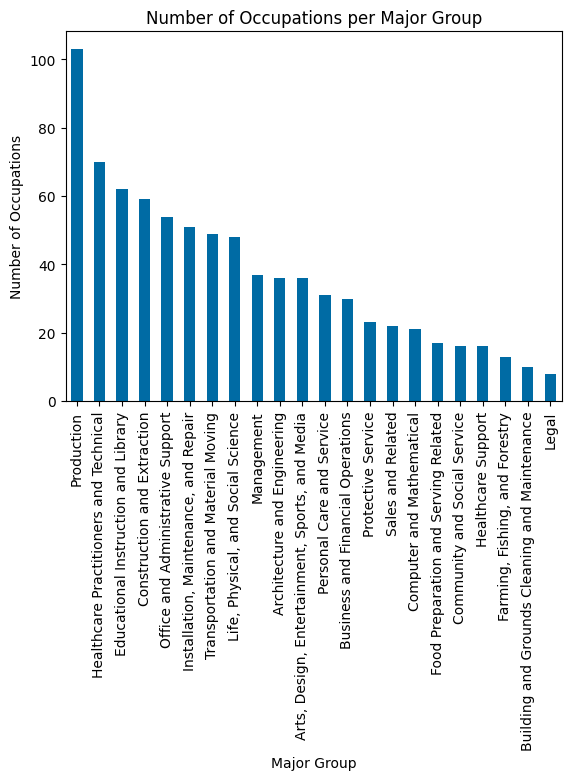

In [24]:
#How many occupations are in each major group?
ai_jobs['Major Group'].value_counts().plot(kind='bar')

plt.title('Number of Occupations per Major Group')
plt.xlabel('Major Group')
plt.ylabel('Number of Occupations')
plt.show()

Vertical bar chart titled "Number of Occupations per Major Group" which shows the count of occupations across 22 major groups, arranged in descending order from Production (103) down to Legal (8).

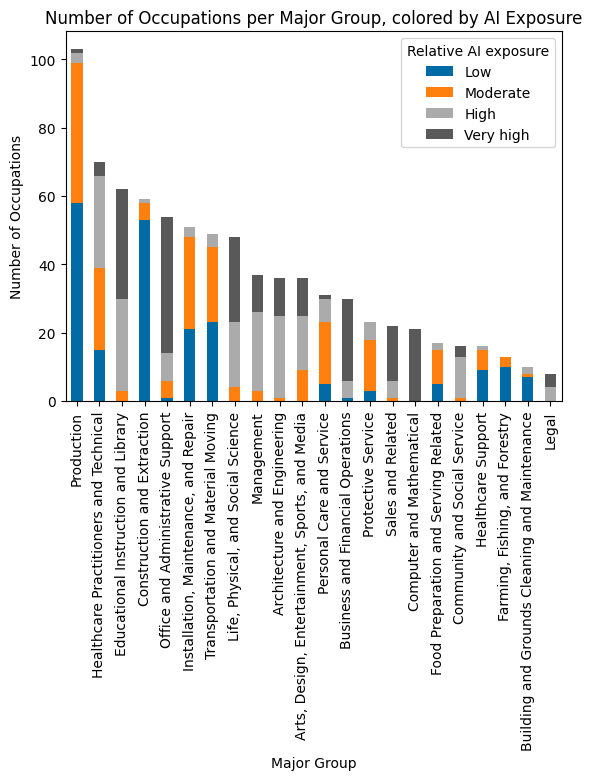

In [25]:
#What is the distribution of AI exposure categories across major groups?
auxiliary_df = (
    ai_jobs.groupby(['Major Group', 'Relative AI exposure'])
    .size()
)

auxiliary_df = auxiliary_df.unstack(fill_value=0)
auxiliary_df = auxiliary_df[['Low', 'Moderate', 'High', 'Very high']]

auxiliary_df = auxiliary_df.loc[
    auxiliary_df.sum(axis=1).sort_values(ascending=False).index
]

auxiliary_df.plot.bar(stacked=True)
plt.title('Number of Occupations per Major Group, colored by AI Exposure')
plt.xlabel('Major Group')
plt.ylabel('Number of Occupations')
plt.style.use('tableau-colorblind10')
plt.show()

Same vertical bar chart, but including stacked bars colored by AI Exposure.

**Summary Statistics:**

In [26]:
jobs_demographic = pd.read_csv('joint_demographic_soc.csv', keep_default_na=False)
jobs_demographic.describe() #Table of summary statistics

,"Employment, 2025","Employment, 2035","Employment change, numeric, 2025-35","Employment change, percent, 2025-35","Occupational openings, 2025-35, annual average","Median annual wage, dollars, 2025",Women,White,Black or African American,Asian,Hispanic or Latino
count,268.000000,268.000000,268.000000,268.000000,268.000000,268.000000,268.000000,268.000000,268.000000,268.000000,268.0000
mean,431.763806,445.004104,13.240672,3.184328,44.477612,70268.992537,48.148507,75.914179,12.611940,7.442164,18.5250
std,651.375271,665.181953,42.951788,7.038597,87.100813,32773.334165,27.896100,9.490777,7.361663,7.267132,10.3102
min,21.900000,22.900000,-200.600000,-34.400000,1.100000,31200.000000,0.600000,25.100000,0.000000,0.000000,3.5000
25%,96.800000,99.425000,0.275000,0.200000,7.675000,45927.500000,22.725000,71.275000,7.475000,3.700000,11.8750
50%,187.300000,200.150000,5.750000,3.800000,16.200000,60705.000000,50.600000,76.550000,11.200000,5.650000,16.0500
75%,437.525000,463.150000,17.825000,6.250000,43.150000,82930.000000,73.425000,81.800000,16.425000,9.400000,21.6000
max,3998.100000,4079.100000,250.700000,41.000000,827.400000,213990.000000,100.000000,96.600000,43.500000,67.500000,66.0000


**Evaluating relationships between race and median annual wage**

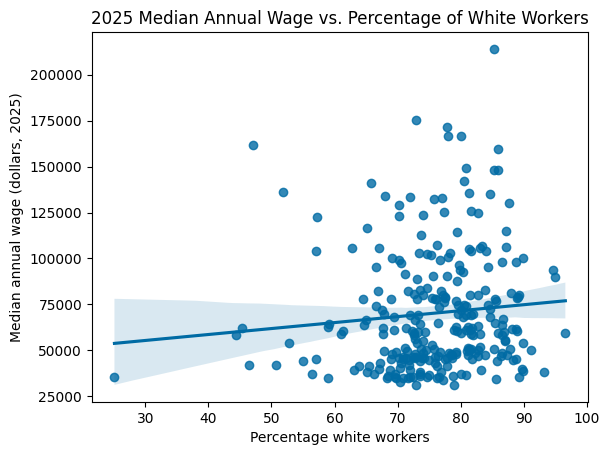

In [27]:
#What is the relationship between the percentage of white workers and median annual wage?
sns.regplot(jobs_demographic,
            x= 'White',
            y = 'Median annual wage, dollars, 2025')

plt.title('2025 Median Annual Wage vs. Percentage of White Workers')
plt.xlabel('Percentage white workers')
plt.ylabel('Median annual wage (dollars, 2025)')
plt.show()

Scatterplot titled '2025 Median Annual Wage vs. Percentage of White Workers,' observations are clustered to the bottom right, with a slightly positive best fit line and large variability. No observable linear correlation.

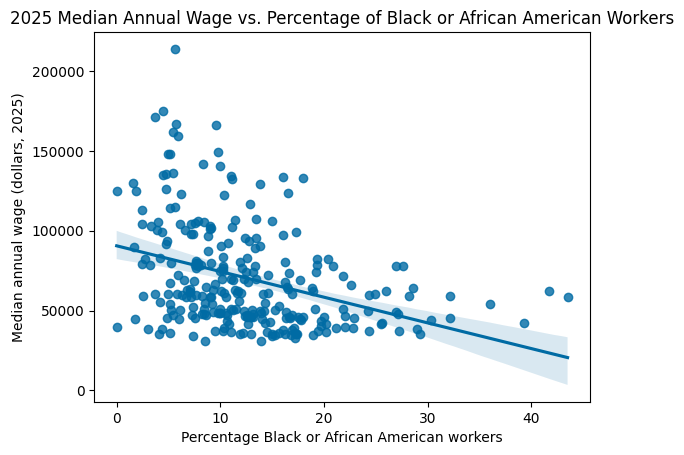

In [28]:
#What is the relationship between the percentage of workers being Black and median annual wage?
sns.regplot(jobs_demographic,
            x= 'Black or African American',
            y = 'Median annual wage, dollars, 2025')

plt.title('2025 Median Annual Wage vs. Percentage of Black or African American Workers')
plt.xlabel('Percentage Black or African American workers')
plt.ylabel('Median annual wage (dollars, 2025)')
plt.show()

Scatterplot titled '2025 Median Annual Wage vs. Percentage of Black or African American Workers,' observations are clustered to the bottom left, with a slightly negative best fit line and large variability. General L-shape in the observations.

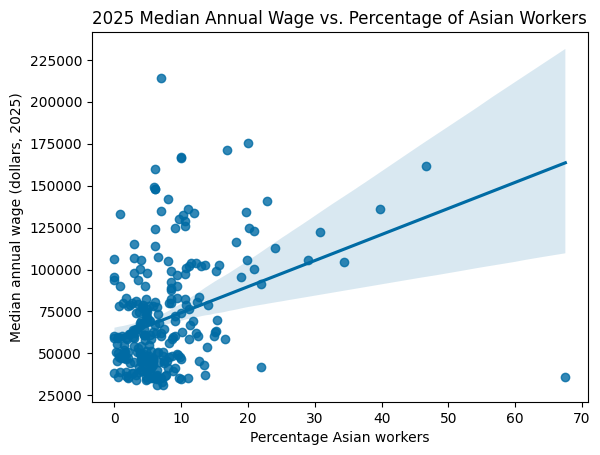

In [29]:
#What is the relationship between the percentage of workers being Asian and median annual wage?
sns.regplot(jobs_demographic,
            x= 'Asian',
            y = 'Median annual wage, dollars, 2025')

plt.title('2025 Median Annual Wage vs. Percentage of Asian Workers')
plt.xlabel('Percentage Asian workers')
plt.ylabel('Median annual wage (dollars, 2025)')
plt.show()

Scatterplot titled '2025 Median Annual Wage vs. Percentage of Asian Workers,' observations are clustered to the bottom left, expanding outward, with a positive best fit line and large variability. No observable shapes or linear correlation.

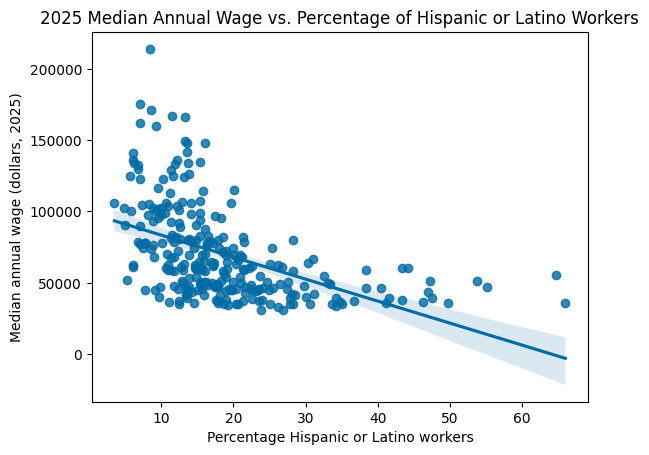

In [30]:
#What is the relationship between the percentage of workers being Hispanic or Latino and median annual wage?
sns.regplot(jobs_demographic,
            x= 'Hispanic or Latino',
            y = 'Median annual wage, dollars, 2025')

plt.title('2025 Median Annual Wage vs. Percentage of Hispanic or Latino Workers')
plt.xlabel('Percentage Hispanic or Latino workers')
plt.ylabel('Median annual wage (dollars, 2025)')
plt.show()

Scatterplot titled '2025 Median Annual Wage vs. Percentage of Hispanic or Latino Workers,' observations are clustered to the bottom left, with a negative best fit line and general L-shape.

**Evaluating relationship between gender and AI exposure**

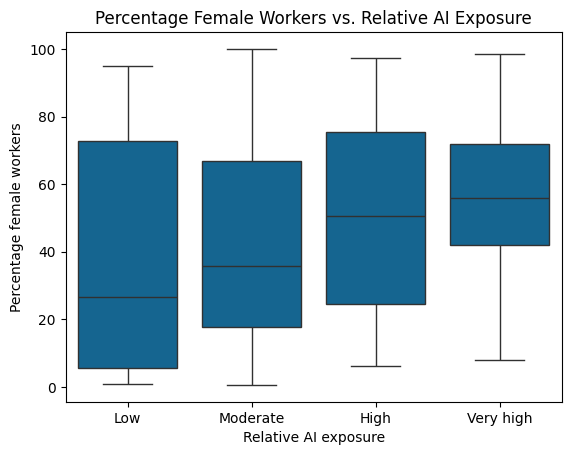

In [31]:
#What is the relationship between gender and relative AI exposure?
sns.boxplot(jobs_demographic,
            x= 'Relative AI exposure',
            y = 'Women',
            order = ['Low','Moderate', 'High', 'Very high'])

plt.title('Percentage Female Workers vs. Relative AI Exposure')
plt.xlabel('Relative AI exposure')
plt.ylabel('Percentage female workers')
plt.show()

Boxplot titled Percentage Female Workers vs. Relative AI Exposure. Boxes grouped by AI Exposure, labeled "Low", "Moderate", "High", and "Very High". Boxes show large variability, with variability decreasing from 'Low' to 'Very High'. General upward trend along the same metric.


**Evaluating relationship between gender and projected change in employment from 2025-35**

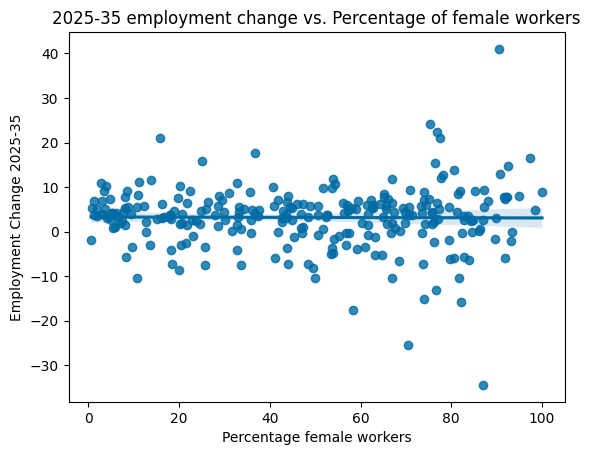

In [32]:
#What is the relationship between gender and projected change in employment from 2025-35?
sns.regplot(jobs_demographic,
            x= 'Women',
            y = 'Employment change, percent, 2025-35')

plt.title('2025-35 employment change vs. Percentage of female workers')
plt.xlabel('Percentage female workers')
plt.ylabel('Employment Change 2025-35')
plt.show()

Scatterplot titled '2025-35 employment change vs. Percentage of female workers', shows a linear correlation with a flat slope, some heteroskedasticity.

**Evaluating relationship between gender and AI exposure**

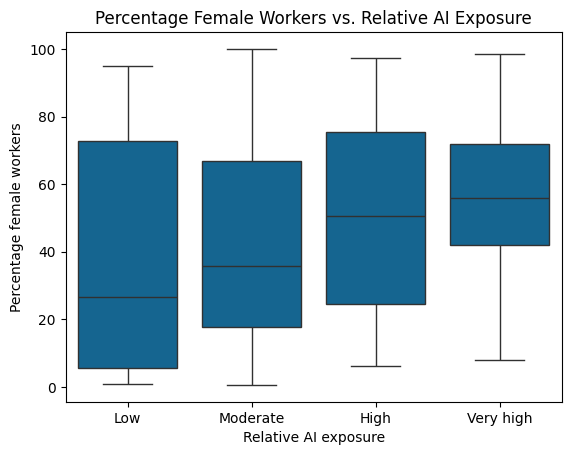

In [33]:
#What is the relationship between gender and relative AI exposure?
sns.boxplot(jobs_demographic,
            x= 'Relative AI exposure',
            y = 'Women',
            order = ['Low','Moderate', 'High', 'Very high'])

plt.title('Percentage Female Workers vs. Relative AI Exposure')
plt.xlabel('Relative AI exposure')
plt.ylabel('Percentage female workers')
plt.show()

Boxplot titled Percentage Female Workers vs. Relative AI Exposure. Boxes grouped by AI Exposure, labeled "Low", "Moderate", "High", and "Very High".


**Evaluating relationship between gender and projected change in employment from 2025-35**

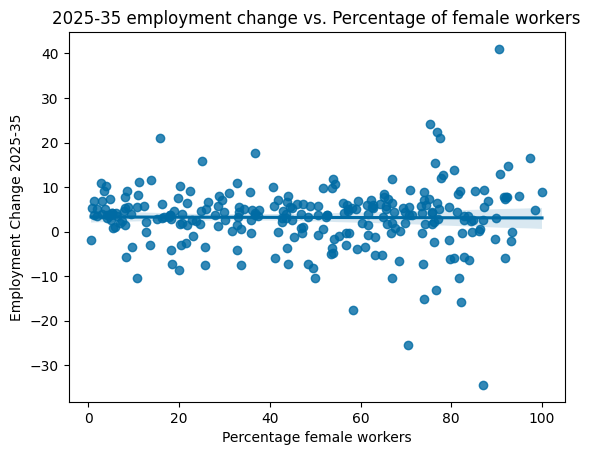

In [34]:
#What is the relationship between gender and projected change in employment from 2025-35?
sns.regplot(jobs_demographic,
            x= 'Women',
            y = 'Employment change, percent, 2025-35')

plt.title('2025-35 employment change vs. Percentage of female workers')
plt.xlabel('Percentage female workers')
plt.ylabel('Employment Change 2025-35')
plt.show()

Scatterplot titled '2025-35 Employment Change  vs. Percentage of female workers.' X axis is Percentage of female workers. Y axis is Employment Change 2025-35. Observations are clustered at the midpoint of 0% changes of employment. There is high variability in percentage of female workers.


**Evaluating relationships between race and projected change in employment from 2025-35**

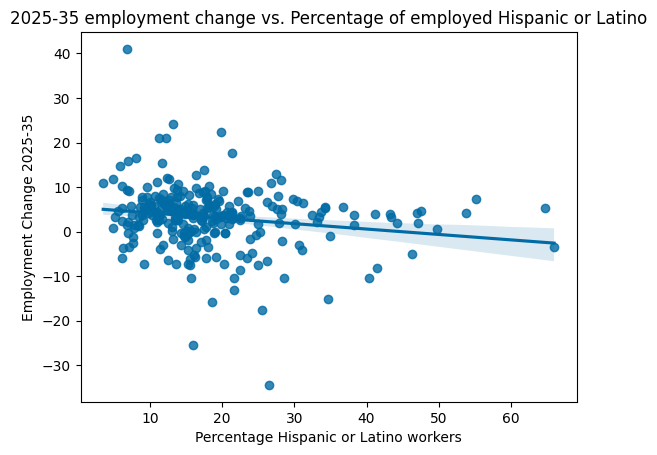

In [35]:
#What is the relationship between the projected change in employment from 2025-35 and workers who are Hispanic or Latino?
sns.regplot(jobs_demographic,
            x= 'Hispanic or Latino',
            y = 'Employment change, percent, 2025-35')

plt.title('2025-35 employment change vs. Percentage of employed Hispanic or Latino')
plt.xlabel('Percentage Hispanic or Latino workers')
plt.ylabel('Employment Change 2025-35')
plt.show()

Scatterplot titled '2025-35 Employment Change  vs. Percentage of Hispanic or Latino workers.'X axis is Percentage of Hispanic or Latino workers. Y axis is Employment Change 2025-35.  Observations are clustered around 10-20%, with a slightly negative slope in change in employment.  


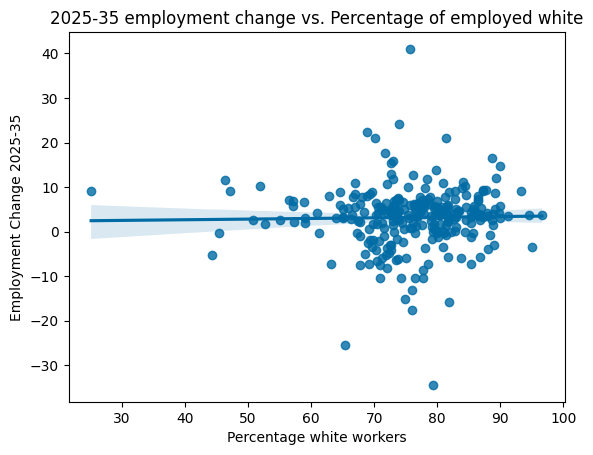

In [36]:
#What is the relationship between the projected change in employment from 2025-35 and workers who are white?
sns.regplot(jobs_demographic,
            x= 'White',
            y = 'Employment change, percent, 2025-35')

plt.title('2025-35 employment change vs. Percentage of employed white')
plt.xlabel('Percentage white workers')
plt.ylabel('Employment Change 2025-35')
plt.show()

Scatterplot titled '2025-35 Employment Change  vs. Percentage of White workers.' X axis is Percentage of white workers. Y axis is Employment Change 2025-35.  Observations are clustered around 70-90%, with no change in employment.


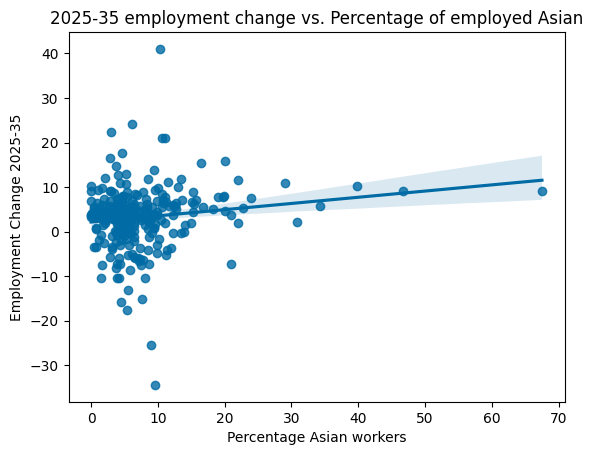

In [37]:
#What is the relationship between the projected change in employment from 2025-35 and workers who are Asian?
sns.regplot(jobs_demographic,
            x= 'Asian',
            y = 'Employment change, percent, 2025-35')

plt.title('2025-35 employment change vs. Percentage of employed Asian')
plt.xlabel('Percentage Asian workers')
plt.ylabel('Employment Change 2025-35')
plt.show()

Scatterplot titled '2025-35 Employment Change vs. Percentage of Asian workers.' X axis is Percentage of white workers. Y axis is Employment Change 2025-35. Observations are clustered around 0-10%, with a slight positive line of best fit.

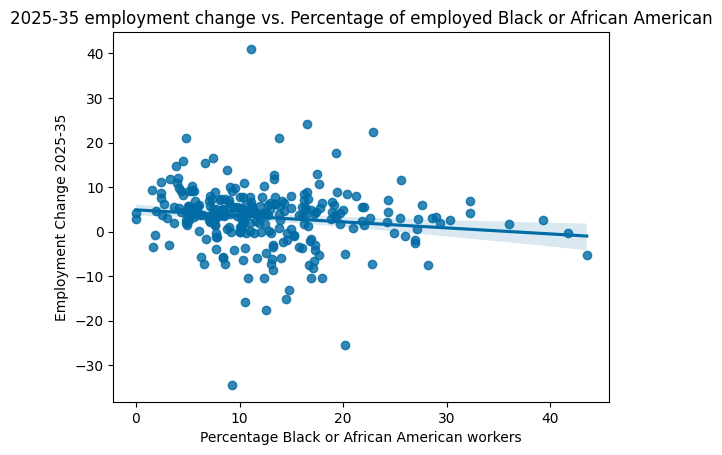

In [38]:
#What is the relationship between the projected change in employment from 2025-35 and workers who are Black?
sns.regplot(jobs_demographic,
            x= 'Black or African American',
            y = 'Employment change, percent, 2025-35')

plt.title('2025-35 employment change vs. Percentage of employed Black or African American')
plt.xlabel('Percentage Black or African American workers')
plt.ylabel('Employment Change 2025-35')
plt.show()

This is a scatter plot with a linear regression line titled “2025-35 employment change vs. Percentage of employed Black or African American.” The x-axis is labelled “Percentage of Black or African American workers,” ranging from 0 to 45 and the y-axis is labelled “Employment Change 2025-35” ranging from -30 to 40, which represents percentage change. Most of the data is concentrated between 5 and 20 on the x axis and -10 and 10 on the y-axis. There is a slight negative slope.


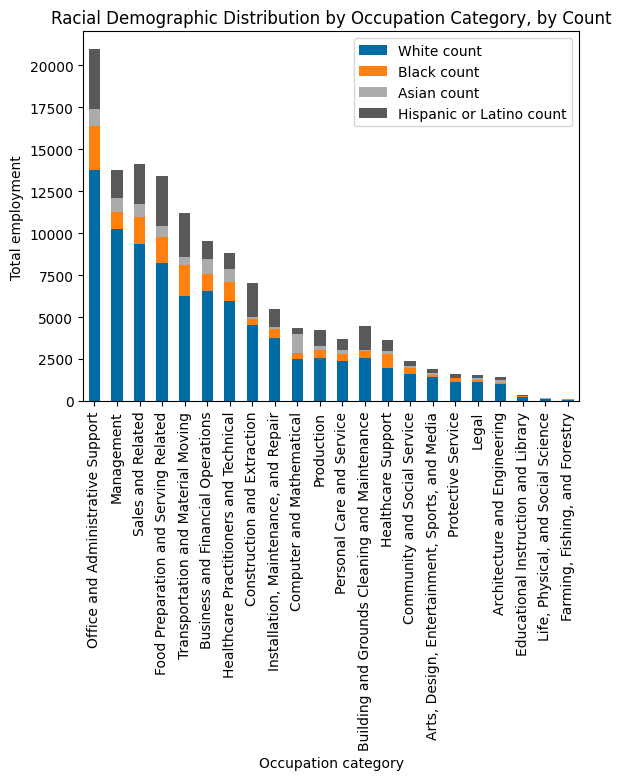

In [39]:
#What is the distribution of racial demographics across major occupation groups?
jobs_copy = jobs_demographic.copy()
jobs_copy['White count'] = jobs_copy['Employment, 2025'] * (jobs_copy['White']/100)
jobs_copy['Black count'] = jobs_copy['Employment, 2025'] * (jobs_copy['Black or African American']/100)
jobs_copy['Asian count'] = jobs_copy['Employment, 2025'] * (jobs_copy['Asian']/100)
jobs_copy['Hispanic or Latino count'] = jobs_copy['Employment, 2025'] * (jobs_copy['Hispanic or Latino']/100)

grouped_sums = jobs_copy.groupby('Major Group')[
    ['Employment, 2025', 'White count', 'Black count', 'Asian count', 'Hispanic or Latino count']
].sum()

grouped_sums = grouped_sums.sort_values(by='Employment, 2025', ascending=False)

grouped_sums_without_total = grouped_sums.drop(columns='Employment, 2025')

grouped_sums_without_total.plot(kind='bar', stacked=True)
plt.title('Racial Demographic Distribution by Occupation Category, by Count')
plt.xlabel('Occupation category')
plt.ylabel('Total employment')
plt.show()



This is a vertical bar chart titled "Racial Demographic Distribution by Occupation Category, by Count" displaying total employment counts across 22 occupation categories. It is  Each  bar is broken down into four racial/ethnic demogrpahic counts, with White represented by the color blue, Black represented by Orange, Asian by light grey, and Hispanic or Latino by dark grey.


**Relationship between education and AI exposure**

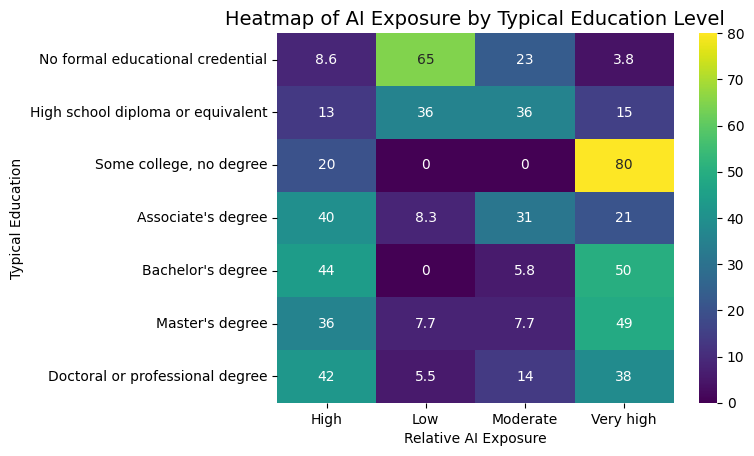

In [40]:
#What is the relationship between typical level of education required and relative AI exposure?
edu_ai_pct = (
    pd.crosstab(
        ai_jobs['Typical education'],
        ai_jobs['Relative AI exposure'],
        normalize='index',
    )* 100
)
education_order = [
    'No formal educational credential',
    'High school diploma or equivalent',
    'Some college, no degree',
    'Associate\'s degree',
    'Bachelor\'s degree',
    'Master\'s degree',
    'Doctoral or professional degree'
]

edu_ai_pct = edu_ai_pct.reindex(education_order)

sns.heatmap(edu_ai_pct, annot=True, cmap='viridis')
plt.title('Heatmap of AI Exposure by Typical Education Level', fontsize=14)
plt.xlabel('Relative AI Exposure')
plt.ylabel('Typical Education')
plt.show()

Annotated heat map titled "Heatmap of AI Exposure by typical Education Level" displaying percentages of occupations across 7 education levels mapped against the four levels of Relative Ai Exposure: High, Low, Moderate, and Very high.  

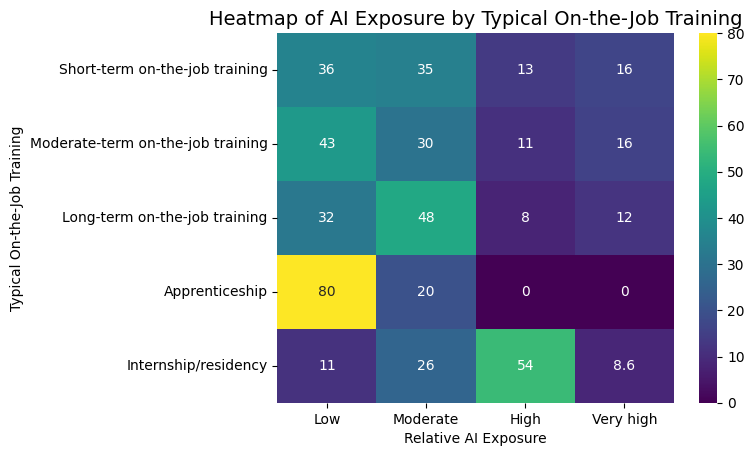

In [41]:
#What is the relationship between level of typical on-the-job training required and relative AI exposure?
training_ai_pct = (
    pd.crosstab(
        ai_jobs['Typical on-the-job training'],
        ai_jobs['Relative AI exposure'],
        normalize='index',
    )* 100
)
training_order = [
    'Short-term on-the-job training',
    'Moderate-term on-the-job training',
    'Long-term on-the-job training',
    'Apprenticeship',
    'Internship/residency',
]

ai_exposure_order = [
    'Low',
    'Moderate',
    'High',
    'Very high'
]

training_ai_pct = training_ai_pct.reindex(training_order) #Order training levels
training_ai_pct = training_ai_pct[ai_exposure_order] #Order AI exposure categories

sns.heatmap(training_ai_pct, annot=True, cmap='viridis')
plt.title('Heatmap of AI Exposure by Typical On-the-Job Training', fontsize=14)
plt.xlabel('Relative AI Exposure')
plt.ylabel('Typical On-the-Job Training')
plt.show()

Annotated heat map titled 'Heatmap of AI Exposure by Typical On-the-Job Training' displaying percentages of occupations across 5 levels of training mapped against the four levels of Relative Ai Exposure: High, Low, Moderate, and Very high.

**Exploring the relationship between AI Exposure and other employment variables**

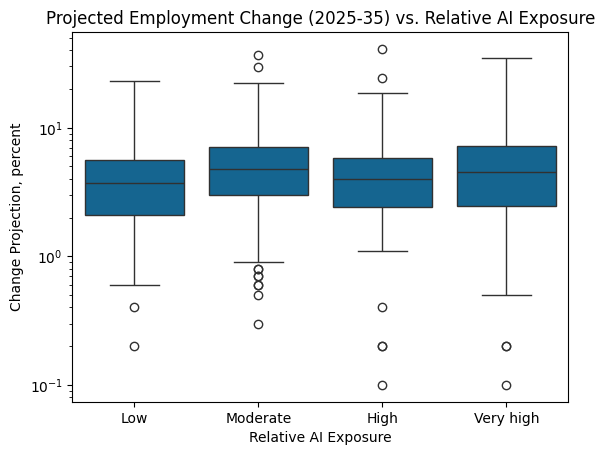

In [42]:
#What is the relationship between Relative AI exposure and Employment change, percent?
sns.boxplot(ai_jobs,
            x= 'Relative AI exposure',
            y = 'Employment change, percent, 2025–35',
            log_scale = True,
            order = ['Low','Moderate', 'High', 'Very high'])

plt.title('Projected Employment Change (2025-35) vs. Relative AI Exposure')
plt.ylabel("Change Projection, percent")
plt.xlabel("Relative AI Exposure")

plt.show()

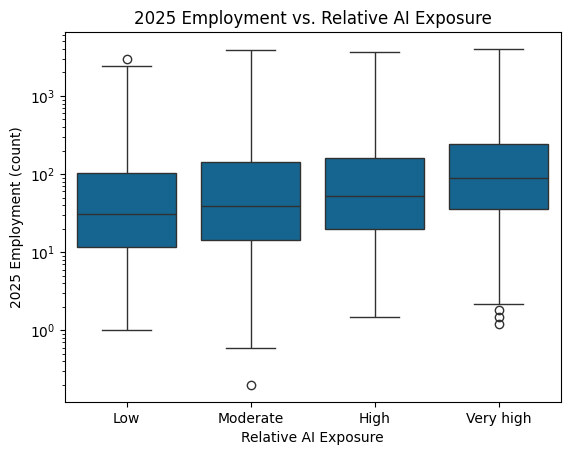

In [43]:
#What is the relationship between Relative AI exposure and Employment counts in 2025?
sns.boxplot(ai_jobs, x= 'Relative AI exposure', y = 'Employment, 2025', log_scale = True, order = ['Low','Moderate', 'High', 'Very high'])

plt.title('2025 Employment vs. Relative AI Exposure')
plt.ylabel("2025 Employment (count)")
plt.xlabel("Relative AI Exposure")

plt.show()

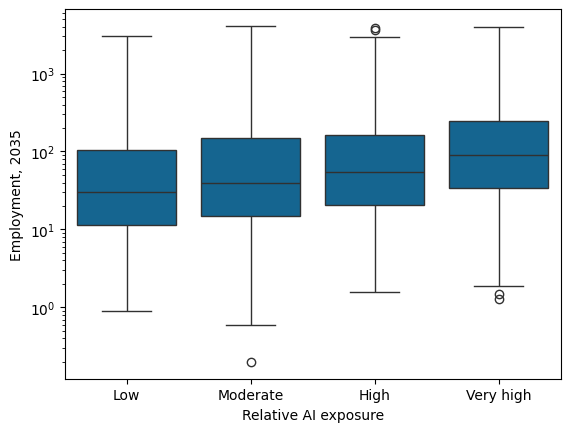

In [44]:
#What is the relationship between Relative AI exposure and projected 2035 employment counts?
sns.boxplot(ai_jobs, x= 'Relative AI exposure', y = 'Employment, 2035', log_scale = True, order = ['Low','Moderate', 'High', 'Very high'])
plt.show()

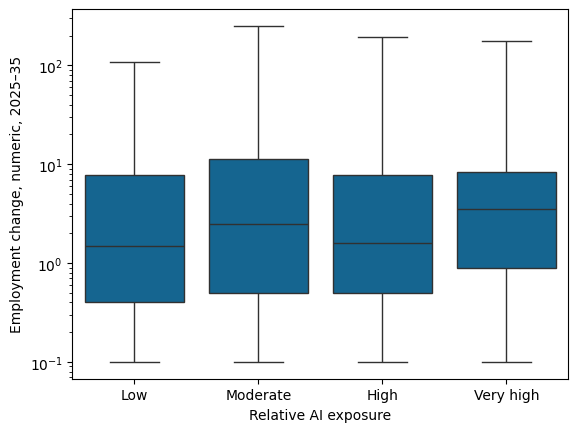

In [45]:
#What is the relationship between Relative AI exposure and numeric employment change between 2025 and 2035?
sns.boxplot(ai_jobs, x= 'Relative AI exposure', y = 'Employment change, numeric, 2025–35', log_scale = True, order = ['Low','Moderate', 'High', 'Very high'])
plt.show()

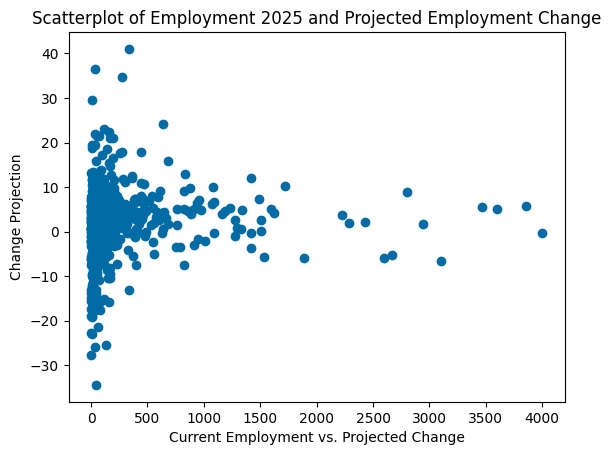

In [46]:
#What is the relationship between current employment (2025) and projected change in employment
plt.scatter(x=ai_jobs['Employment, 2025'], y= ai_jobs['Employment change, percent, 2025–35'])
plt.title('Scatterplot of Employment 2025 and Projected Employment Change')
plt.ylabel("Change Projection")
plt.xlabel("Current Employment vs. Projected Change")
plt.show()

In [47]:
# dividing into two dataframes of lower and higher AI exposure
ai_lower = ai_jobs[ai_jobs['Relative AI exposure'].isin(['Low', 'Moderate'])]
ai_higher = ai_jobs[ai_jobs['Relative AI exposure'].isin(['High', 'Very high'])]

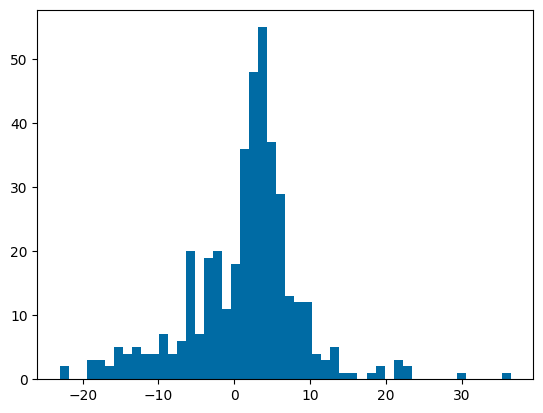

In [48]:
# distribution of employment change percent within lower AI exposure jobs
plt.hist(x=ai_lower['Employment change, percent, 2025–35'], bins = 50)
plt.show()

In [49]:
# std for above distribution
np.std(ai_lower['Employment change, percent, 2025–35'])

7.414517573698518

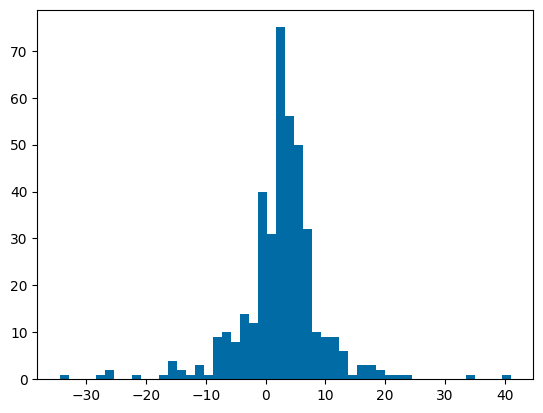

In [50]:
# distribution of employment change percent within lower AI exposure jobs
plt.hist(x=ai_higher['Employment change, percent, 2025–35'], bins = 50)
plt.show()

In [51]:
# std for above distribution
np.std(ai_higher['Employment change, percent, 2025–35'])

7.057261335916835

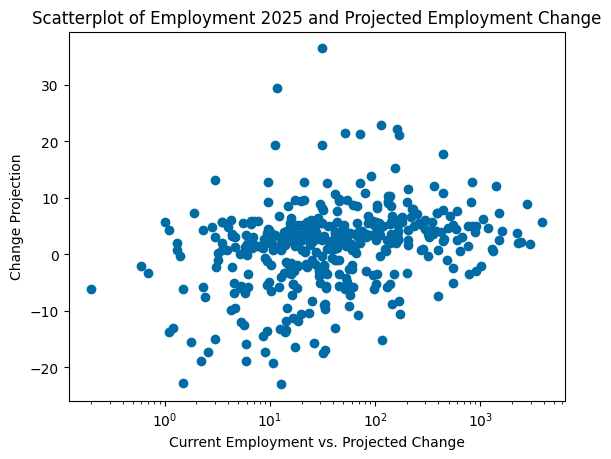

In [52]:
# How does projected employment change relate to current employment
# within lower AI exposure jobs?
plt.scatter(x=ai_lower['Employment, 2025'], y= ai_lower['Employment change, percent, 2025–35'])
plt.xscale('log')
plt.title('Scatterplot of Employment 2025 and Projected Employment Change')
plt.ylabel("Change Projection")
plt.xlabel("Current Employment vs. Projected Change")
plt.show()

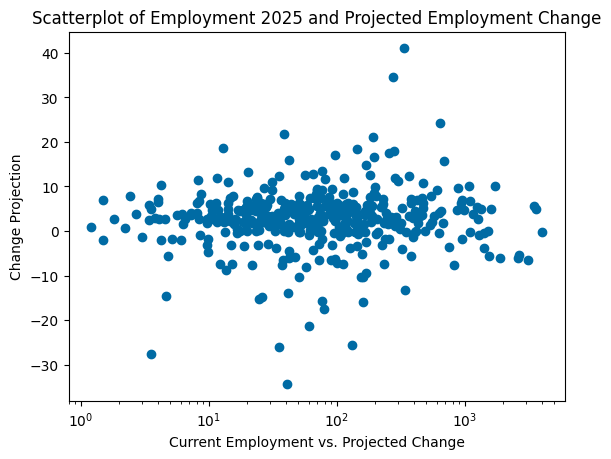

In [53]:
# How does projected employment change relate to current employment
# within higher AI exposure jobs?
plt.scatter(x=ai_higher['Employment, 2025'], y= ai_higher['Employment change, percent, 2025–35'])
plt.xscale('log')
plt.title('Scatterplot of Employment 2025 and Projected Employment Change')
plt.ylabel("Change Projection")
plt.xlabel("Current Employment vs. Projected Change")
plt.show()

In [54]:
import statsmodels.formula.api as smf

In [55]:
# linear regression for employment change percent predicted by current employment
import statsmodels.api as sm

X = np.log(ai_jobs['Employment, 2025'])
X = sm.add_constant(X)
y = ai_jobs['Employment change, percent, 2025–35']

model_employment = sm.OLS(y, X).fit()

model_employment.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                     OLS Regression Results                                    
===============================================================================================
Dep. Variable:     Employment change, percent, 2025–35   R-squared:                       0.041
Model:                                             OLS   Adj. R-squared:                  0.040
Method:                                  Least Squares   F-statistic:                     34.51
Date:                                 Thu, 15 Oct 2026   Prob (F-statistic):           6.18e-09
Time:                                         04:10:48   Log-Likelihood:                -2745.6
No. Observations:                                  812   AIC:                             5495.
Df Residuals:                                      810   BIC:                             5505.
Df Model:                                            1                                         
Covariance Type:                             nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -1.4835      0.648     -2.289      0.022      -2.756      -0.211
Employment, 2025     0.8880      0.151      5.875      0.000       0.591       1.185
==============================================================================
Omnibus:                       88.145   Durbin-Watson:                   1.149
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              579.852
Skew:                          -0.197   Prob(JB):                    1.22e-126
Kurtosis:                       7.121   Cond. No.                         11.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [56]:
# linear regression for employment change percent predicted by current employment
# within lower AI exposure jobs
X = np.log(ai_lower['Employment, 2025'])
X = sm.add_constant(X)
y = ai_lower['Employment change, percent, 2025–35']

model_lower = sm.OLS(y, X).fit()

model_lower.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                     OLS Regression Results                                    
===============================================================================================
Dep. Variable:     Employment change, percent, 2025–35   R-squared:                       0.089
Model:                                             OLS   Adj. R-squared:                  0.087
Method:                                  Least Squares   F-statistic:                     40.09
Date:                                 Thu, 15 Oct 2026   Prob (F-statistic):           6.40e-10
Time:                                         04:10:48   Log-Likelihood:                -1384.0
No. Observations:                                  410   AIC:                             2772.
Df Residuals:                                      408   BIC:                             2780.
Df Model:                                            1                                         
Covariance Type:                             nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -3.3805      0.836     -4.046      0.000      -5.023      -1.738
Employment, 2025     1.3091      0.207      6.332      0.000       0.903       1.716
==============================================================================
Omnibus:                       30.936   Durbin-Watson:                   1.361
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              118.429
Skew:                           0.125   Prob(JB):                     1.92e-26
Kurtosis:                       5.621   Cond. No.                         10.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [57]:
# linear regression for employment change percent predicted by current employment
# within higher AI exposure jobs
X = np.log(ai_higher['Employment, 2025'])
X = sm.add_constant(X)
y = ai_higher['Employment change, percent, 2025–35']

model_higher = sm.OLS(y, X).fit()

model_higher.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                     OLS Regression Results                                    
===============================================================================================
Dep. Variable:     Employment change, percent, 2025–35   R-squared:                       0.004
Model:                                             OLS   Adj. R-squared:                  0.002
Method:                                  Least Squares   F-statistic:                     1.701
Date:                                 Thu, 15 Oct 2026   Prob (F-statistic):              0.193
Time:                                         04:10:48   Log-Likelihood:                -1355.1
No. Observations:                                  402   AIC:                             2714.
Df Residuals:                                      400   BIC:                             2722.
Df Model:                                            1                                         
Covariance Type:                             nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                1.3971      1.023      1.366      0.173      -0.613       3.408
Employment, 2025     0.2947      0.226      1.304      0.193      -0.149       0.739
==============================================================================
Omnibus:                       74.431   Durbin-Watson:                   1.005
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              729.444
Skew:                          -0.416   Prob(JB):                    4.01e-159
Kurtosis:                       9.546   Cond. No.                         13.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [58]:
# grouping jobs by major group and taking mean employment change percent
category_change = ai_jobs.groupby('Major Group', as_index = False)[
    'Employment change, percent, 2025–35'].mean().sort_values('Employment change, percent, 2025–35')

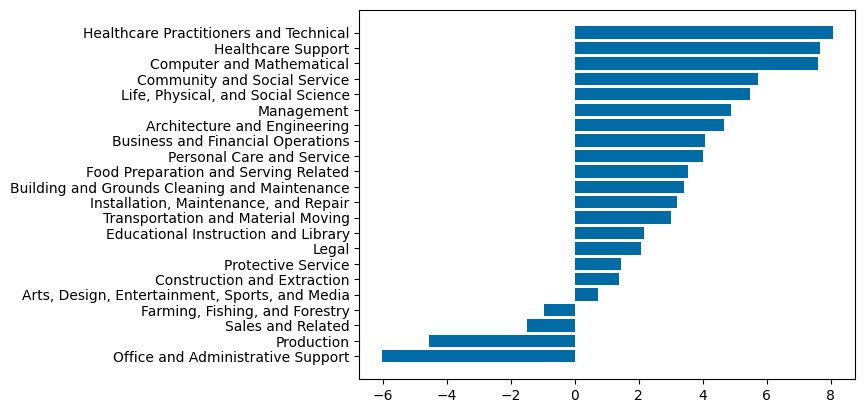

In [59]:
# exployment change percent for each major occupation group

plt.barh(category_change['Major Group'], category_change['Employment change, percent, 2025–35'])
plt.show()

In [60]:
# loading in data from similar graphs for past years/projections
proj_2034 = pd.read_csv('bls_2024_occupations.csv')
proj_2033 = pd.read_csv('bls_2023_occupations.csv')
proj_2032 = pd.read_csv('bls_2022_occupations.csv')

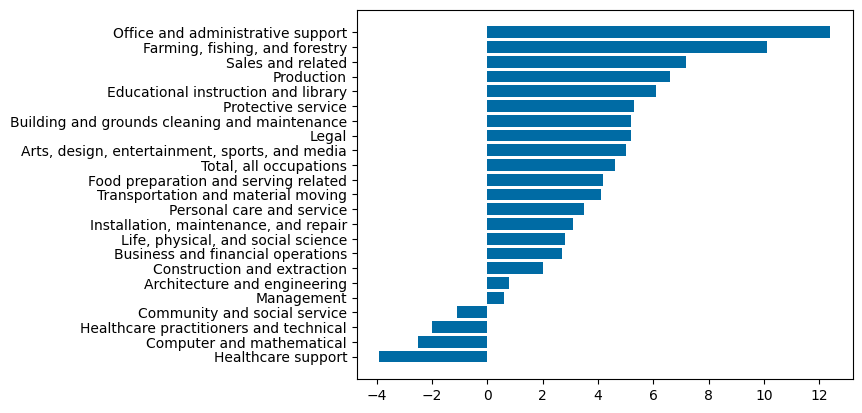

In [61]:
# same plot for 2024-34
plt.barh(proj_2034['Occupation'], proj_2034['Percent change, 2024–34'].sort_values())
plt.show()

In [62]:
# dropping na for 2023-33 plot
proj_2033 = proj_2033.dropna()

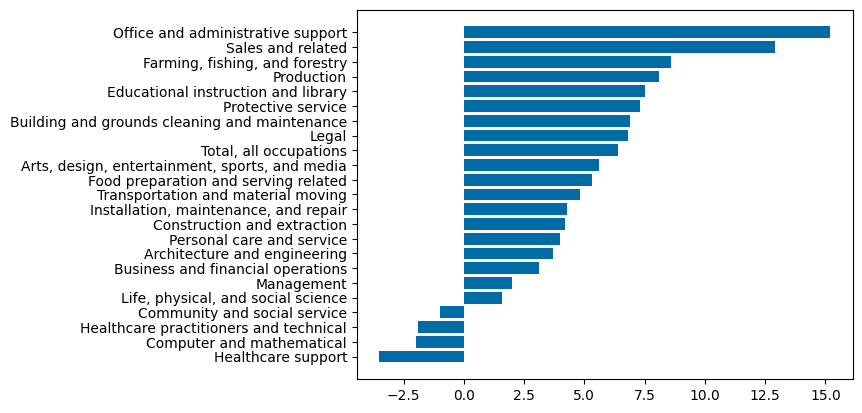

In [63]:
# same plot for 2023-33
plt.barh(proj_2033['Occupation'], proj_2033['Percent change, 2023–33'].sort_values())
plt.show()

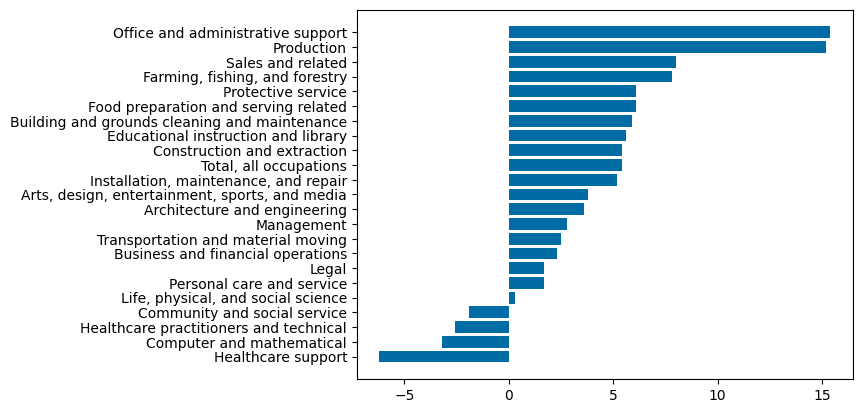

In [64]:
# same plot for 2022-32
plt.barh(proj_2032['Occupation'], proj_2032['Percent change, 2022–32'].sort_values())
plt.show()

In [65]:
# calculation of median for variable annual wage
wage_median = np.median(ai_jobs['Median annual wage, dollars, 2025'])

In [66]:
# creating column splitting wages into low vs high, based on median
wage_diff = ai_jobs
wage_diff.loc[ai_jobs['Median annual wage, dollars, 2025'] >= wage_median, 'Wage Category'] = "High"
wage_diff.loc[ai_jobs['Median annual wage, dollars, 2025'] < wage_median, 'Wage Category'] = "Low"

In [67]:
# separating low and high wage groups into datasets
low_wage = wage_diff[wage_diff['Wage Category'] == 'Low']
high_wage = wage_diff[wage_diff['Wage Category'] == 'High']

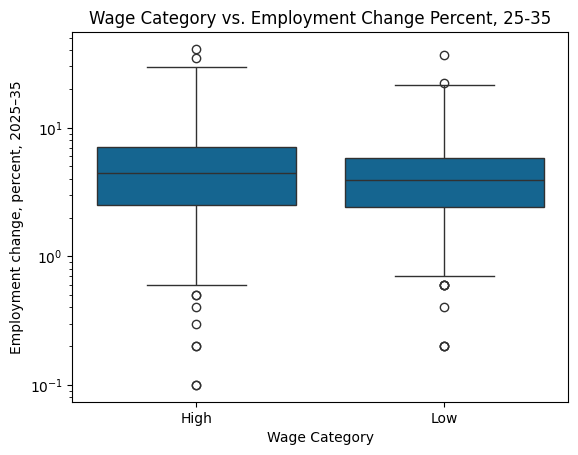

In [68]:
# How does employment change percent differ based on wage category?
sns.boxplot(wage_diff, x= 'Wage Category', y = 'Employment change, percent, 2025–35', log_scale = True)
plt.title('Wage Category vs. Employment Change Percent, 25-35')
plt.show()

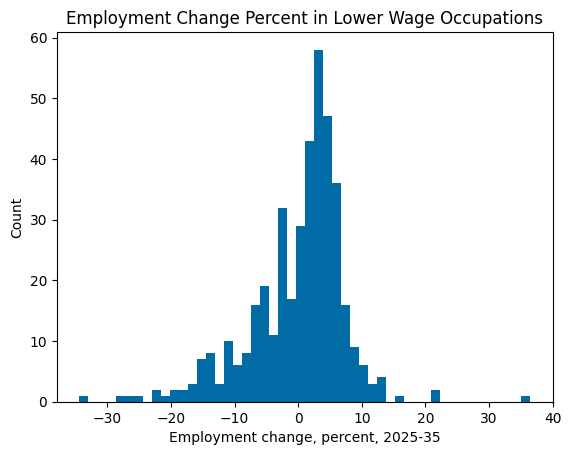

In [69]:
# What is the distribution of Employment change percent among lower wage jobs?
plt.hist(x=low_wage['Employment change, percent, 2025–35'], bins = 50)
plt.xlabel('Employment change, percent, 2025-35')
plt.ylabel('Count')
plt.title('Employment Change Percent in Lower Wage Occupations')
plt.show()

Histogram titled 'Employment Change Percent in Lower Wage Occupations'. General normal distribution with slight left skew.

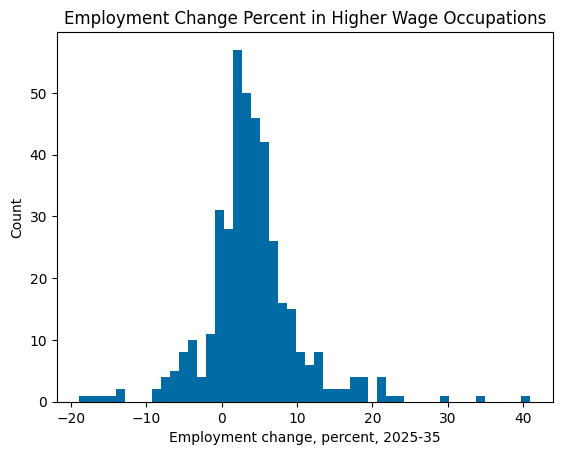

In [70]:
# What is the distribution of Employment change percent among higher wage jobs?
plt.hist(x=high_wage['Employment change, percent, 2025–35'], bins = 50)
plt.xlabel('Employment change, percent, 2025-35')
plt.ylabel('Count')
plt.title('Employment Change Percent in Higher Wage Occupations')
plt.show()

Histogram titled 'Employment Change Percent in Higher Wage Occupations'. General normal distribution with slight right skew.

In [71]:
# comparing median employment change percent between high and low wage category
np.median(low_wage['Employment change, percent, 2025–35']), np.median(high_wage['Employment change, percent, 2025–35'])

(np.float64(1.95), np.float64(3.6500000000000004))

In [72]:
# comparing mean employment change percent between high and low wage category
np.mean(low_wage['Employment change, percent, 2025–35']), np.mean(high_wage['Employment change, percent, 2025–35'])

(np.float64(0.013054187192118184), np.float64(4.04704433497537))

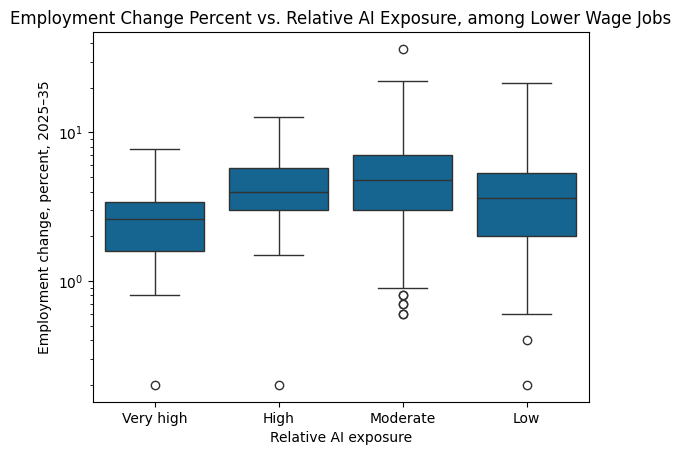

In [73]:
# How does employment change percent differ among different AI Exposure
# categories, within  lower wage jobs?
sns.boxplot(low_wage, x= 'Relative AI exposure',
            y = 'Employment change, percent, 2025–35',
            log_scale = True, order = ['Very high', 'High', 'Moderate', 'Low'])
plt.title('Employment Change Percent vs. Relative AI Exposure, among Lower Wage Jobs')
plt.show()

Box plot titled 'Relative AI Exposure vs. Employment Change Percent, among Lower Wage Jobs,' with boxes "Low", "Moderate", "High", and "Very High". Boxes demonstrate a curve from left to right, with "High" and "Moderate" appearing to have higher Employment change percent.

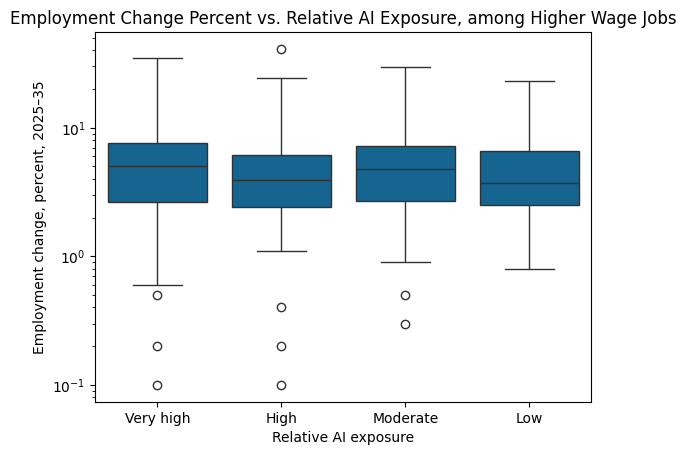

In [74]:
# How does employment change percent differ among different AI Exposure
# categories, within  higher wage jobs?
sns.boxplot(high_wage, x= 'Relative AI exposure',
            y = 'Employment change, percent, 2025–35',
            log_scale = True, order = ['Very high', 'High', 'Moderate', 'Low'])
plt.title('Employment Change Percent vs. Relative AI Exposure, among Higher Wage Jobs')
plt.show()

Box plot titled 'Relative AI Exposure vs. Employment Change Percent, among Higher Wage Jobs,' with boxes "Low", "Moderate", "High", and "Very High". Boxes appear equal across the conditions.